# 04 - Análisis exploratorio de datos (EDA)

Antes de entrenar cualquier modelo, miramos los datos de `demanda_gold` para entenderlos. Queremos responder seis preguntas:

| Sección | Pregunta |
|---|---|
| 1. Calidad | ¿Faltan datos? ¿Dónde y por qué? |
| 2. Lo que queremos predecir | ¿Cómo se reparten los valores de `pasajeros`? ¿Conviene transformarlo? |
| 3. Patrones en el tiempo | ¿Cómo cambia la cantidad de pasajeros según la hora y el tipo de día? |
| 4. Líneas | ¿Qué tan distintas son las líneas entre sí? |
| 5. Calendario y clima | ¿Las clases, los feriados y la lluvia cambian la cantidad de pasajeros? |
| 6. Relación entre variables | ¿Qué variables se parecen a `pasajeros`? ¿Cuáles dicen lo mismo entre sí? |

**Regla importante: el EDA se hace solo con `train`.** Si miramos val o test para decidir cosas (qué variables usar, qué transformación hacer), estamos haciendo trampa sin querer. Val y test se usan recién en los notebooks 05 y 06.

In [0]:
%run ./00_setup

# 00 - Preparar el proyecto

Este notebook deja todo listo para que los demás funcionen. Hace cuatro cosas:

1. Le dice a Python dónde está nuestro código (la carpeta `src/bondis`), para poder escribir `from bondis import ...`.
2. Crea en Databricks el lugar donde se guardan las tablas y los archivos (`bondis_stm.datos.raw`, definido en `config.py`).
3. Crea una carpeta para cada tipo de archivo (viajes, clima, etc.).
4. Muestra cómo dividimos los datos en train, val y test.

Se puede correr todas las veces que quieras. Si algo ya existe, no lo vuelve a crear ni lo borra.

No hace falta abrirlo a mano: los otros notebooks lo corren al principio con `%run ./00_setup`.

## 1. Encontrar nuestro código

Python solo puede importar código de las carpetas que conoce. Esta celda busca la carpeta del repositorio subiendo carpeta por carpeta hasta encontrar `src/bondis`, y la agrega a la lista de carpetas que Python conoce (`sys.path`).

## 2. Crear el catálogo, el esquema y el volume

Databricks ordena todo en tres niveles, como carpetas una dentro de otra:

- **Catálogo** (`bondis_stm`): la carpeta grande del proyecto.
- **Esquema** (`datos`): una subcarpeta donde van las tablas.
- **Volume** (`raw`): una carpeta para guardar archivos sueltos, como los ZIP y CSV que bajamos.


## 3. Crear una carpeta para cada tipo de archivo

| Carpeta | Qué va adentro |
|---|---|
| `viajes_zip/` | Los ZIP de viajes de cada mes, bajados a mano del portal de la Intendencia |
| `viajes/` | Los CSV de viajes, ya sacados de los ZIP |
| `clima/` | Lluvia y temperatura de cada hora |
| `calendario/` | Por ahora vacía. El calendario está escrito en `src/bondis/calendario.py` |
| `paros/` | Días y horas con paro (todavía no lo hicimos) |

## 4. Revisar que todo esté bien

Muestra la versión de Spark, el usuario y cuántos archivos hay en cada carpeta. Sirve para ver de un vistazo si falta subir algo.

## 5. Cómo dividimos los datos

Usamos las fechas para dividir, no el azar, porque queremos predecir el futuro con el pasado. Un año entero para cada cosa:

| Conjunto | Fechas | Para qué se usa |
|---|---|---|
| `train` | todo 2024 | El modelo aprende con estos datos |
| `val` | todo 2025 | Comparamos y elegimos los parámetros de la regresión |
| `test` | 2026 (lo que haya) | Probamos el modelo elegido una sola vez, al final |

La fecha de fin **no** está incluida. Por eso siempre se filtra con `fecha >= inicio` y `fecha < fin`.

`train_final` es train + val juntos. Cuando ya elegimos el modelo, lo volvemos a entrenar con 2024 y 2025 antes de probarlo en 2026.

... (8 outputs left out)

## 2. Crear el catálogo, el esquema y el volume

Databricks ordena todo en tres niveles, como carpetas una dentro de otra:

- **Catálogo** (`bondis_stm`): la carpeta grande del proyecto.
- **Esquema** (`datos`): una subcarpeta donde van las tablas.
- **Volume** (`raw`): una carpeta para guardar archivos sueltos, como los ZIP y CSV que bajamos.


## 3. Crear una carpeta para cada tipo de archivo

| Carpeta | Qué va adentro |
|---|---|
| `viajes_zip/` | Los ZIP de viajes de cada mes, bajados a mano del portal de la Intendencia |
| `viajes/` | Los CSV de viajes, ya sacados de los ZIP |
| `clima/` | Lluvia y temperatura de cada hora |
| `calendario/` | Por ahora vacía. El calendario está escrito en `src/bondis/calendario.py` |
| `paros/` | Vacía. Al final no usamos paros, porque en los de estos años los ómnibus anduvieron normal (ver `calendario.py`) |

## 4. Revisar que todo esté bien

Muestra la versión de Spark, el usuario y cuántos archivos hay en cada carpeta. Sirve para ver de un vistazo si falta subir algo.

## 5. Cómo dividimos los datos

Usamos las fechas para dividir, no el azar, porque queremos predecir el futuro con el pasado. Un año entero para cada cosa:

| Conjunto | Fechas | Para qué se usa |
|---|---|---|
| `train` | todo 2024 | El modelo aprende con estos datos |
| `val` | todo 2025 | Comparamos y elegimos los parámetros de la regresión |
| `test` | 2026 (lo que haya) | Probamos el modelo elegido una sola vez, al final |

La fecha de fin **no** está incluida. Por eso siempre se filtra con `fecha >= inicio` y `fecha < fin`.

`train_final` es train + val juntos. Cuando ya elegimos el modelo, lo volvemos a entrenar con 2024 y 2025 antes de probarlo en 2026.

In [0]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.sql import functions as F

from bondis import variables

spark.conf.set("spark.sql.session.timeZone", config.TIMEZONE)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

# El tipo de día (hábil, sábado, domingo, turismo, feriado) se calcula en src/bondis/variables.py.
# Usamos la misma función en todos los notebooks para que siempre signifique lo mismo.
TIPOS_DIA = variables.TIPOS_DIA
con_tipo_dia = variables.con_tipo_dia
COLORES = {"hábil": "tab:blue", "sábado": "tab:orange", "domingo": "tab:green",
           "turismo": "tab:purple", "feriado": "tab:red"}


gold = spark.table(config.TABLE_GOLD)
train = con_tipo_dia(gold.where(F.col("particion") == "train")).cache()

# Pasajeros de todo el sistema por día. Lo usan varias secciones de abajo.
por_dia = (
    train.groupBy("fecha", "tipo_dia", "dia_semana", "es_feriado", "es_eleccion",
                  "clases_primaria", "clases_media", "nombre_dia_especial")
    .agg(F.sum("pasajeros").alias("pasajeros"))
    .toPandas()
    .sort_values("fecha")
)
por_dia["fecha"] = pd.to_datetime(por_dia["fecha"])
print(f"Días en train: {len(por_dia)}")

Días en train: 366


## 1. Calidad de los datos

Lo que esperamos encontrar:
- **Muchos ceros**: por las horas de la madrugada y por líneas que no andan todos los días. Es normal.
- **Rezagos vacíos** en las primeras 4 semanas de 2024: no hay días anteriores para mirar.
- **Clima vacío** antes del 19/01/2024: ahí empiezan los pronósticos guardados.
- **`nombre_dia_especial` vacío** casi siempre: solo tiene algo en días especiales (feriados, elecciones).
- **Columnas `ayer_...` vacías** solo el 01/01/2024, porque no armamos el calendario de 2023.

Si aparece algún otro vacío, es una sorpresa y hay que investigarlo antes de seguir.

In [0]:
r = train.agg(
    F.count("*").alias("filas"),
    F.countDistinct("linea").alias("lineas"),
    F.min("fecha").alias("desde"),
    F.max("fecha").alias("hasta"),
    F.sum("pasajeros").alias("pasajeros"),
    F.avg((F.col("pasajeros") == 0).cast("int")).alias("prop_ceros"),
    F.avg(F.col("fila_completa").cast("int")).alias("prop_completas"),
    F.min(F.when(F.col("fila_completa"), F.col("fecha"))).alias("primera_completa"),
).first()

print(f"Filas:                {r['filas']:,}")
print(f"Líneas:               {r['lineas']}")
print(f"Fechas:               {r['desde']} a {r['hasta']}")
print(f"Pasajeros:            {r['pasajeros']:,}")
print(f"Horas con 0 pasajeros: {r['prop_ceros']:.1%}")
print(f"Filas completas:      {r['prop_completas']:.1%} (desde {r['primera_completa']})")

nulos = train.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in train.columns]).first().asDict()
nulos = pd.Series(nulos)
nulos = (nulos[nulos > 0] / r["filas"]).sort_values(ascending=False).rename("proporción vacía")
print("\nColumnas con vacíos:")
print(nulos.map("{:.2%}".format).to_string())

Filas:                1,194,624
Líneas:               136
Fechas:               2024-01-01 a 2024-12-31
Pasajeros:            306,259,563
Horas con 0 pasajeros: 24.3%
Filas completas:      91.9% (desde 2024-01-29)

Columnas con vacíos:
nombre_dia_especial             93.17%
pasajeros_lag_28d                7.65%
pasajeros_prom_4sem              7.65%
pasajeros_mediana_4sem           7.65%
pasajeros_lag_21d                5.74%
temperatura_pron                 5.02%
lluvia_pron_mm                   5.00%
llueve_pron                      5.00%
lluvia_pron_dia_mm               5.00%
pasajeros_lag_14d                3.83%
pasajeros_lag_7d                 1.91%
ayer_es_no_laborable             0.27%
ayer_es_carnaval                 0.27%
ayer_es_turismo                  0.27%
pasajeros_lag_1d                 0.27%
pasajeros_linea_dia_anterior     0.27%


## 2. Lo que queremos predecir: `pasajeros`

Calculamos algunos números para describir cómo se reparten los valores:

- **Media**: el promedio.
- **Mediana**: el valor del medio si ordenamos todo de menor a mayor. La mitad de las horas tiene menos y la otra mitad tiene más.
- **Desvío**: qué tan lejos de la media están los valores, en promedio.
- **Asimetría**: dice si los datos están "torcidos" para un lado. Si da cerca de 0, el histograma es parejo a los dos lados. Si da positiva y grande, hay una **cola larga a la derecha**: muchas horas con pocos pasajeros y pocas horas con muchísimos.
- **Curtosis**: dice qué tanto pesan los valores muy extremos. Si da alta, hay valores muy grandes que se alejan mucho del resto.

**¿Por qué nos importa?** Si la media es mucho más grande que la mediana, hay pocas horas pico con muchísima gente. Esas horas dominan el error del modelo. Una solución es usar $\log(1 + \text{pasajeros})$ en lugar de `pasajeros`. El logaritmo achica los números grandes mucho más que los chicos (por ejemplo, 10 pasa a 2,4 y 1000 pasa a 6,9), y así el histograma queda más parejo. Usamos 1 + pasajeros porque el logaritmo de 0 no existe. Si lo usamos, al final deshacemos la transformación para que el error se mida siempre en pasajeros.

In [0]:
d = train.agg(
    F.mean("pasajeros").alias("media"),
    F.stddev("pasajeros").alias("desvio"),
    F.skewness("pasajeros").alias("asimetria"),
    F.kurtosis("pasajeros").alias("curtosis"),
    F.max("pasajeros").alias("maximo"),
    F.expr("percentile_approx(pasajeros, array(0.25, 0.5, 0.75, 0.9, 0.99))").alias("q"),
).first()
q25, q50, q75, q90, q99 = d["q"]

print(f"Media:     {d['media']:8.1f}    Mediana: {q50}")
print(f"Desvío:    {d['desvio']:8.1f}    Q1 / Q3: {q25} / {q75}")
print(f"Asimetría: {d['asimetria']:8.2f}    P90 / P99: {q90} / {q99}")
print(f"Curtosis:  {d['curtosis']:8.2f}    Máximo: {d['maximo']}")

Media:        256.4    Mediana: 69
Desvío:       386.9    Q1 / Q3: 2 / 351
Asimetría:     1.99    P90 / P99: 853 / 1613
Curtosis:      3.87    Máximo: 4052


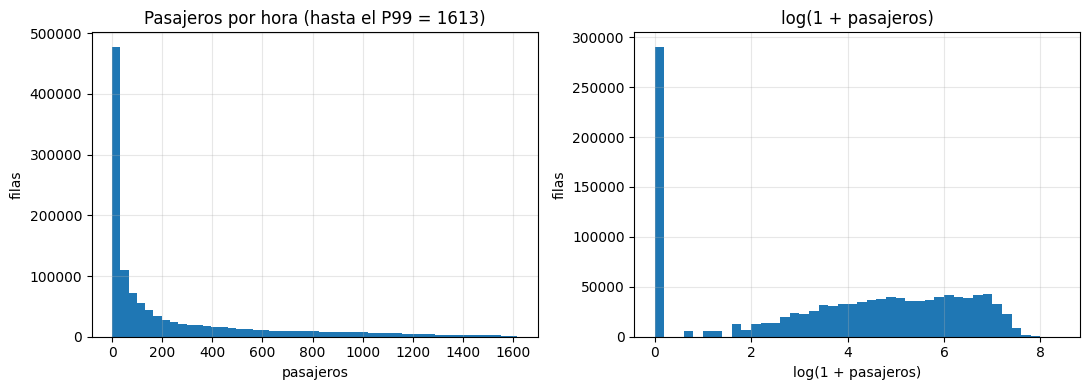

In [0]:
# Los histogramas se calculan en Spark y solo se traen los conteos, así es rápido
ancho = max(1, int(np.ceil(q99 / 50)))
hist_lin = (train.where(F.col("pasajeros") <= q99)
            .groupBy((F.floor(F.col("pasajeros") / ancho) * ancho).alias("x")).count()
            .toPandas().sort_values("x"))
hist_log = (train.groupBy((F.floor(F.log1p("pasajeros") * 5) / 5).alias("x")).count()
            .toPandas().sort_values("x"))

fig, (a1, a2) = plt.subplots(1, 2)
a1.bar(hist_lin["x"], hist_lin["count"], width=ancho, align="edge")
a1.set(title=f"Pasajeros por hora (hasta el P99 = {q99})", xlabel="pasajeros", ylabel="filas")
a2.bar(hist_log["x"], hist_log["count"], width=0.2, align="edge")
a2.set(title="log(1 + pasajeros)", xlabel="log(1 + pasajeros)", ylabel="filas")
plt.tight_layout()
plt.show()

## 3. Patrones en el tiempo

### 3.1 Pasajeros por hora según el tipo de día

Para cada tipo de día, el promedio de pasajeros de todo el sistema en cada hora. Qué mirar:
- ¿Los días hábiles tienen dos picos (mañana y tarde)? ¿A qué hora?
- ¿Los sábados y domingos tienen otra **forma**, o solo tienen menos gente?

**¿Por qué importa?** Si las curvas tienen formas distintas, no alcanza con un modelo que diga "la hora suma tanto y el tipo de día suma tanto". Ejemplo: a las 7 de la mañana un día hábil está lleno, pero un domingo está vacío. El efecto de la hora **depende** del tipo de día. A eso se le llama **interacción** entre hora y tipo de día. En el modelo lineal hay que agregarla a mano.

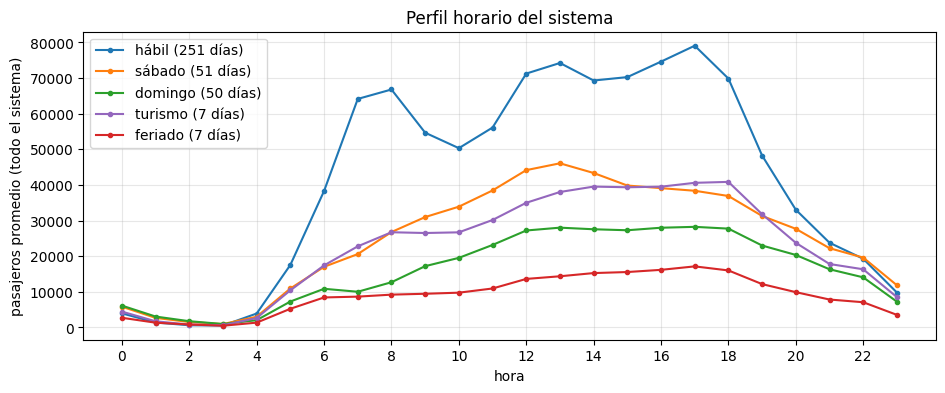

In [0]:
perfil = (
    train.groupBy("fecha", "tipo_dia", "hora").agg(F.sum("pasajeros").alias("p"))
    .groupBy("tipo_dia", "hora").agg(F.avg("p").alias("pasajeros"), F.countDistinct("fecha").alias("dias"))
    .toPandas()
)

fig, ax = plt.subplots()
for t in TIPOS_DIA:
    s = perfil[perfil["tipo_dia"] == t].sort_values("hora")
    if len(s):
        ax.plot(s["hora"], s["pasajeros"], marker="o", ms=3, color=COLORES[t], label=f"{t} ({s['dias'].iloc[0]} días)")
ax.set(title="Perfil horario del sistema", xlabel="hora", ylabel="pasajeros promedio (todo el sistema)",
       xticks=range(0, 24, 2))
ax.legend()
plt.show()

### 3.2 Pasajeros de cada día

Total de todo el sistema, día por día, en train. Qué mirar:
- El ciclo de la semana (bajan los fines de semana).
- Los días muy bajos: ¿todos tienen explicación en el calendario (feriados, Turismo, días sin ómnibus)? Si hay un día bajo **sin explicación**, puede ser un paro. Hay que anotarlo.
- Cambios de nivel: el comienzo de las clases en marzo, las vacaciones de julio.

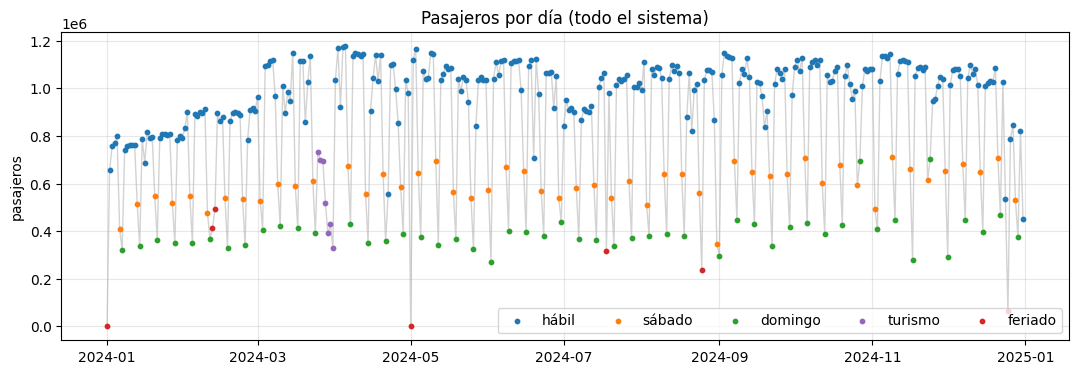

Días hábiles con menos del 70 % de la mediana de su mes:
     fecha  pasajeros  ratio                                         nombre_dia_especial
2024-04-22     554712  0.504 Desembarco de los 33 Orientales (trasladado del viernes 19)
2024-06-19     708417  0.654                                        Natalicio de Artigas
2024-12-24     537078  0.522                                          Víspera de Navidad
2024-12-31     452050  0.439                                                  Fin de Año


In [0]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(por_dia["fecha"], por_dia["pasajeros"], color="lightgray", lw=1, zorder=1)
for t in TIPOS_DIA:
    s = por_dia[por_dia["tipo_dia"] == t]
    ax.scatter(s["fecha"], s["pasajeros"], s=10, color=COLORES[t], label=t, zorder=2)
ax.set(title="Pasajeros por día (todo el sistema)", ylabel="pasajeros")
ax.legend(ncol=5)
plt.show()

# Días hábiles muy bajos (menos del 70 % de lo normal en su mes). Podrían ser paros.
habiles = por_dia[por_dia["tipo_dia"] == "hábil"].copy()
habiles["mediana_mes"] = habiles.groupby(habiles["fecha"].dt.month)["pasajeros"].transform("median")
habiles["ratio"] = habiles["pasajeros"] / habiles["mediana_mes"]
bajos = habiles[habiles["ratio"] < 0.7][["fecha", "pasajeros", "ratio", "nombre_dia_especial"]]
print("Días hábiles con menos del 70 % de la mediana de su mes:")
print(bajos.round({"ratio": 3}).to_string(index=False) if len(bajos) else "  ninguno")

### 3.3 ¿Lo que pasó ayer sirve como pista?

Uno pensaría que lo que pasó ayer es una buena pista para hoy. Para un martes común puede ser, porque se parece al lunes. Pero un lunes no se parece en nada al domingo, y el día después de un feriado tampoco se parece al feriado.

Para verlo agrupamos los días según qué tipo de día fue ayer y qué tipo es hoy, y calculamos dos cocientes:

- `hoy_sobre_ayer`: pasajeros de hoy dividido pasajeros de ayer, en la misma línea y hora. Si da cerca de 1, ayer es buena pista.
- `hoy_sobre_mediana`: lo mismo pero contra la mediana de 4 semanas, para tener con qué comparar.

Si `hoy_sobre_ayer` se aleja mucho de 1 en algunos cambios (por ejemplo de domingo a hábil), una regresión que le da siempre el mismo peso al rezago de 1 día se va a equivocar justo en esos días. Por eso en el modelo le avisamos qué tipo de día fue ayer.

In [0]:
cambios = (
    train.where(F.col("fila_completa"))
    .groupBy("tipo_dia_ayer", "tipo_dia")
    .agg(F.countDistinct("fecha").alias("dias"),
         (F.sum("pasajeros") / F.sum("pasajeros_lag_1d")).alias("hoy_sobre_ayer"),
         (F.sum("pasajeros") / F.sum("pasajeros_mediana_4sem")).alias("hoy_sobre_mediana"))
    .toPandas()
    .sort_values(["tipo_dia", "dias"], ascending=[True, False])
)
print("Pasajeros de hoy comparados con ayer y con la mediana, según el tipo de día de ayer y de hoy:")
print(cambios.round(3).to_string(index=False))

Pasajeros de hoy comparados con ayer y con la mediana, según el tipo de día de ayer y de hoy:
tipo_dia_ayer tipo_dia  dias  hoy_sobre_ayer  hoy_sobre_mediana
       sábado  domingo    46           0.654              1.050
        hábil  feriado     3           0.147              0.123
      domingo  feriado     1           1.117              0.511
      feriado  feriado     1           1.199              0.619
       sábado  feriado     1           0.418              0.620
        hábil    hábil   181           1.007              1.007
      domingo    hábil    45           2.518              1.003
      feriado    hábil     5           4.352              0.973
      turismo    hábil     1           3.162              1.002
        hábil   sábado    47           0.582              1.009
      turismo  turismo     6           0.883              0.607
      domingo  turismo     1           1.873              0.713


## 4. Diferencias entre líneas

Qué mirar:
- **Concentración**: ¿cuántos pasajeros llevan las 10 o 20 líneas más grandes? Si es la mayoría, el error total del modelo lo van a decidir esas pocas líneas.
- **Media contra desvío**: si las líneas con más pasajeros también varían más (los puntos forman una recta en el gráfico), el error de cada línea crece con su tamaño. Es otra razón para usar $\log(1 + \text{pasajeros})$.

Las 10 líneas más grandes llevan el 23.6% de los pasajeros
Las 20 líneas más grandes llevan el 41.7% de los pasajeros
Las 50 líneas más grandes llevan el 80.4% de los pasajeros


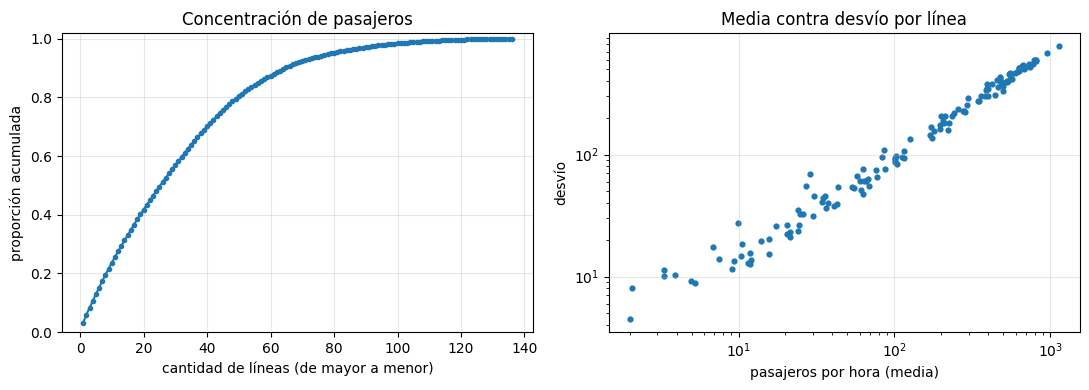

Las 5 líneas más chicas:
linea  total  media_hora  prop_ceros
  106  34342    3.909608    0.767532
  L23  29153    3.318875    0.892532
  140  29087    3.311362    0.847678
  135  18179    2.069558    0.901867
   G6  17648    2.009107    0.785747


In [0]:
lineas = (
    train.groupBy("linea", "tipo_linea")
    .agg(F.sum("pasajeros").alias("total"),
         F.avg("pasajeros").alias("media_hora"),
         F.stddev("pasajeros").alias("desvio_hora"),
         F.avg((F.col("pasajeros") == 0).cast("int")).alias("prop_ceros"))
    .toPandas().sort_values("total", ascending=False).reset_index(drop=True)
)
lineas["acumulado"] = lineas["total"].cumsum() / lineas["total"].sum()
for k in (10, 20, 50):
    if k <= len(lineas):
        print(f"Las {k} líneas más grandes llevan el {lineas['acumulado'].iloc[k - 1]:.1%} de los pasajeros")

fig, (a1, a2) = plt.subplots(1, 2)
a1.plot(np.arange(1, len(lineas) + 1), lineas["acumulado"], marker=".")
a1.set(title="Concentración de pasajeros", xlabel="cantidad de líneas (de mayor a menor)",
       ylabel="proporción acumulada", ylim=(0, 1.02))
a2.scatter(lineas["media_hora"], lineas["desvio_hora"], s=12)
a2.set(title="Media contra desvío por línea", xlabel="pasajeros por hora (media)",
       ylabel="desvío", xscale="log", yscale="log")
plt.tight_layout()
plt.show()

print("Las 5 líneas más chicas:")
print(lineas.tail(5)[["linea", "total", "media_hora", "prop_ceros"]].to_string(index=False))

## 5. Calendario y clima

### 5.1 Clases y feriados

Promedio de pasajeros por día según el tipo de día y si hay clases. Qué mirar:
- En días hábiles, ¿cuánta más gente viaja cuando hay clases?
- Los feriados laborables (el comercio abre), ¿se parecen más a un día hábil o a un domingo?
- Los domingos de elecciones, ¿son distintos a un domingo común?

In [0]:
def tabla(df, por):
    return (df.groupby(por)["pasajeros"].agg(dias="count", promedio="mean")
            .round(0).astype({"promedio": "int64"}))

h = por_dia[por_dia["tipo_dia"] == "hábil"]
print("Días hábiles, según clases:")
print(tabla(h, ["clases_primaria", "clases_media"]).to_string(), "\n")

print("Días hábiles, feriado laborable o no:")
print(tabla(h, ["es_feriado"]).to_string(), "\n")

print("Domingos, con elecciones o sin:")
print(tabla(por_dia[por_dia["dia_semana"] == 7], ["es_eleccion"]).to_string())

Días hábiles, según clases:
                              dias  promedio
clases_primaria clases_media                
False           False           61    847660
True            False           15   1007376
                True           175   1053754 

Días hábiles, feriado laborable o no:
            dias  promedio
es_feriado                
False        249   1003862
True           2    631564 

Domingos, con elecciones o sin:
             dias  promedio
es_eleccion                
False          49    371489
True            3    612780


### 5.2 Lluvia y temperatura pronosticadas

**El problema.** Si comparamos directo los días con lluvia y sin lluvia, se mezclan otras cosas. Por ejemplo, en invierno llueve más, y en invierno también hay clases. Entonces no sabríamos si la diferencia es por la lluvia o por las clases.

**La solución.** Comparamos cada día con lo que es "normal" para ese día:

$$\text{cociente del día} = \frac{\text{pasajeros del día}}{\text{suma de las medianas de 4 semanas del día}}$$

La mediana de las 4 semanas anteriores (misma línea, misma hora, mismo día de la semana) ya tiene en cuenta la época del año y el día de la semana. Si el cociente da 0,95, ese día viajó un 5 % menos de gente que lo normal. Si da 1,10, un 10 % más. Se usan solo días hábiles con filas completas.

**Cuidado con los cambios de época.** La mediana mira 4 semanas para atrás. El primer mes de clases se compara con semanas de vacaciones, así que el cociente sale alto aunque no haya pasado nada con el clima. Como marzo es caluroso, parecería que el calor hace viajar más gente, y es mentira. Por eso se sacan los días en que el estado de las clases (primaria y media) no es igual al de las 4 semanas con las que se comparan.

Siempre hay que mirar la columna `dias`. Si hay pocos días en un grupo, una diferencia de 2 o 3 puntos puede ser casualidad.

In [0]:
clima_dia = (
    con_tipo_dia(gold.where((F.col("particion") == "train") & F.col("fila_completa")))
    .where(F.col("tipo_dia") == "hábil")
    .groupBy("fecha")
    .agg((F.sum("pasajeros") / F.sum("pasajeros_mediana_4sem")).alias("cociente"),
         F.first("lluvia_pron_dia_mm").alias("lluvia_dia"),
         F.avg("temperatura_pron").alias("temp_media"))
    .toPandas()
)
clima_dia["fecha"] = pd.to_datetime(clima_dia["fecha"])

# Solo dejamos los días que tienen el mismo estado de clases que 7, 14, 21 y 28 días antes
estado = por_dia.set_index("fecha")[["clases_primaria", "clases_media"]]


def regimen_estable(f):
    refs = [f - pd.Timedelta(days=k) for k in (7, 14, 21, 28)]
    return all(r in estado.index and (estado.loc[r] == estado.loc[f]).all() for r in refs)


antes = len(clima_dia)
if antes == 0:
    raise ValueError(
        "No hay días hábiles completos en train, así que no se puede comparar el clima. "
        "Lo más probable es que el pronóstico del clima no cubra 2024. "
        "Hay que revisar la tabla 'Pronóstico por partición' del notebook 03."
    )
# El astype(bool) hace que pandas lo use siempre como filtro de filas, aunque quede vacío
clima_dia = clima_dia[clima_dia["fecha"].map(regimen_estable).astype(bool)]
print(f"Días hábiles completos: {antes}. Con el mismo estado de clases que en las 4 semanas anteriores: {len(clima_dia)}\n")
clima_dia["lluvia"] = pd.cut(clima_dia["lluvia_dia"], [-0.01, 0.1, 5, 20, np.inf],
                             labels=["seco (< 0,1 mm)", "0,1 a 5 mm", "5 a 20 mm", "más de 20 mm"])
clima_dia["temperatura"] = pd.cut(clima_dia["temp_media"], [-np.inf, 10, 15, 20, 25, np.inf],
                                  labels=["< 10 °C", "10 a 15", "15 a 20", "20 a 25", "> 25 °C"])

for col in ("lluvia", "temperatura"):
    t = clima_dia.groupby(col, observed=False)["cociente"].agg(dias="count", cociente_medio="mean")
    print(f"Días hábiles por {col} pronosticada:")
    print(t.round(3).to_string(), "\n")

Días hábiles completos: 232. Con el mismo estado de clases que en las 4 semanas anteriores: 152

Días hábiles por lluvia pronosticada:
                 dias  cociente_medio
lluvia                               
seco (< 0,1 mm)    77           1.038
0,1 a 5 mm         56           1.020
5 a 20 mm          17           0.893
más de 20 mm        2           0.837 

Días hábiles por temperatura pronosticada:
             dias  cociente_medio
temperatura                      
< 10 °C        14           0.991
10 a 15        52           1.001
15 a 20        45           1.014
20 a 25        34           1.017
> 25 °C         7           1.109 



## 6. Relación entre variables

Usamos la **correlación de Pearson**. Es un número entre -1 y 1 que dice qué tan bien dos variables se acomodan sobre una línea recta:
- Cerca de 1: cuando una sube, la otra también sube.
- Cerca de -1: cuando una sube, la otra baja.
- Cerca de 0: no hay relación en línea recta.

Se calcula sobre una muestra de 200.000 filas completas de train. Lo miramos de dos formas:

1. **Con `pasajeros`**: qué variables se mueven junto con lo que queremos predecir.
2. **Entre ellas**: si dos variables son casi iguales (correlación cerca de 1), dicen lo mismo. En una regresión lineal eso es un problema, porque el modelo no sabe a cuál darle el peso y los coeficientes quedan inestables (cambian mucho con cambios chicos en los datos). Ejemplo: `pasajeros_prom_4sem` es exactamente el promedio de los rezagos de 7, 14, 21 y 28 días. No tiene sentido poner los cinco juntos en una regresión lineal.

**Cuidado con la hora.** Su correlación con `pasajeros` va a dar baja, aunque la hora es de lo que más importa (ver 3.1). Pasa porque la correlación solo mide relaciones en línea recta, y los pasajeros por hora tienen forma de dos montañas (mañana y tarde). Un número solo no alcanza para describir una relación, siempre hay que mirar el gráfico.

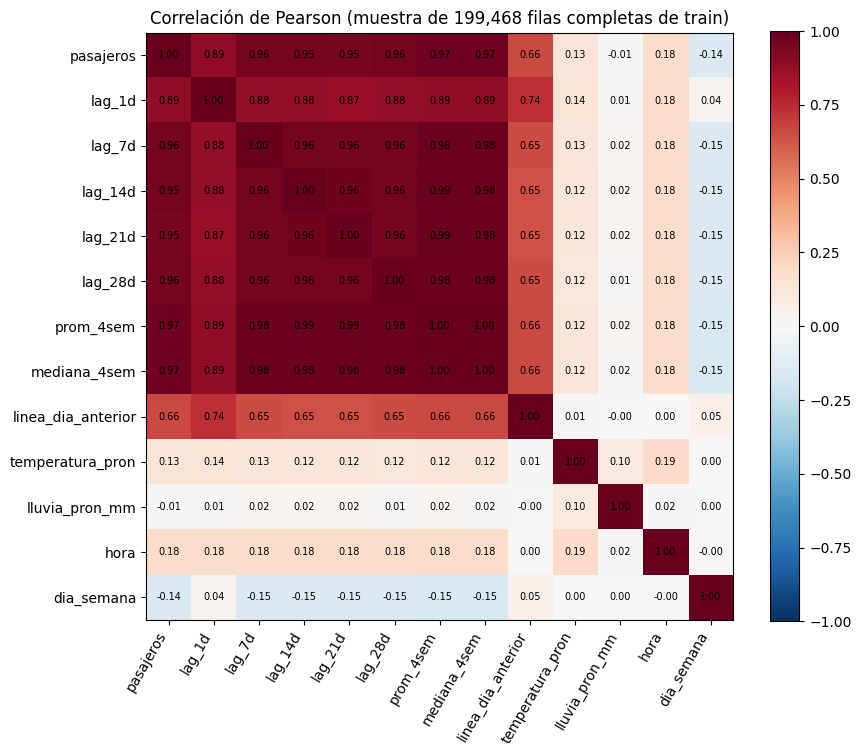

Correlación con pasajeros:
pasajeros_mediana_4sem          0.972
pasajeros_prom_4sem             0.971
pasajeros_lag_28d               0.959
pasajeros_lag_7d                0.957
pasajeros_lag_14d               0.954
pasajeros_lag_21d               0.952
pasajeros_lag_1d                0.887
pasajeros_linea_dia_anterior    0.657
hora                            0.181
temperatura_pron                0.127
lluvia_pron_mm                 -0.010
dia_semana                     -0.144


In [0]:
NUMERICAS = [
    "pasajeros",
    "pasajeros_lag_1d", "pasajeros_lag_7d", "pasajeros_lag_14d", "pasajeros_lag_21d", "pasajeros_lag_28d",
    "pasajeros_prom_4sem", "pasajeros_mediana_4sem", "pasajeros_linea_dia_anterior",
    "temperatura_pron", "lluvia_pron_mm", "hora", "dia_semana",
]
completas = train.where(F.col("fila_completa"))
n = completas.count()
muestra = (completas.sample(fraction=min(1.0, 200_000 / max(n, 1)), seed=config.SEED)
           .select(*NUMERICAS).toPandas().astype(float))
corr = muestra.corr()

nombres = [c.replace("pasajeros_", "") for c in NUMERICAS]
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(nombres)), nombres, rotation=60, ha="right")
ax.set_yticks(range(len(nombres)), nombres)
ax.grid(False)
for i in range(len(nombres)):
    for j in range(len(nombres)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im)
ax.set_title(f"Correlación de Pearson (muestra de {len(muestra):,} filas completas de train)")
plt.tight_layout()
plt.show()

print("Correlación con pasajeros:")
print(corr["pasajeros"].drop("pasajeros").sort_values(ascending=False).round(3).to_string())

In [0]:
train.unpersist()

DataFrame[linea: string, fecha: date, hora: int, particion: string, fila_completa: boolean, linea_en_marcha: boolean, pasajeros: bigint, anio: int, mes: int, dia_mes: int, dia_semana: int, es_fin_de_semana: boolean, es_feriado: boolean, es_no_laborable: boolean, es_carnaval: boolean, es_turismo: boolean, es_eleccion: boolean, es_dia_sin_servicio: boolean, es_vispera_navidad: boolean, es_fin_de_anio: boolean, es_semana_fiestas: boolean, clases_primaria: boolean, clases_media: boolean, nombre_dia_especial: string, ayer_es_no_laborable: boolean, ayer_es_carnaval: boolean, ayer_es_turismo: boolean, tipo_linea: string, temperatura_pron: double, lluvia_pron_mm: double, llueve_pron: boolean, lluvia_pron_dia_mm: double, pasajeros_lag_1d: bigint, pasajeros_lag_7d: bigint, pasajeros_lag_14d: bigint, pasajeros_lag_21d: bigint, pasajeros_lag_28d: bigint, pasajeros_prom_4sem: double, pasajeros_mediana_4sem: double, pasajeros_linea_dia_anterior: bigint, validaciones: bigint, tipo_dia: string, tipo_d